# Linear Algebra for Data Science
## Eigenvalues, Principal Component Analysis, and Singular Value Decomposition

**Author:** Muhammad Abdullah Zahid

This project explores three linear algebra techniques that underpin many
data science and machine learning methods:

1. **Eigenvalues and eigenvectors:** Implement the Power Method to estimate
   a dominant eigenpair and compare it with NumPy.
2. **Principal Component Analysis (PCA):** Implement PCA through covariance
   eigendecomposition and compare it with scikit-learn.
3. **Singular Value Decomposition (SVD):** Construct an educational SVD
   implementation through eigendecomposition and compare it with NumPy.

The analysis uses small example matrices, reproducible synthetic data,
and the Iris dataset. Results are assessed using numerical accuracy checks,
visualizations, and repeated runtime measurements.

The PCA and SVD implementations use NumPy's eigendecomposition routines
as building blocks. They demonstrate the mathematical steps rather than
implementing every numerical solver from scratch.

## 1. Setup

Import the libraries, configure plotting, and create a folder for exported
figures. Random seeds make the examples reproducible.

In [1]:
# Library imports
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA

# Reproducibility and display settings
RANDOM_STATE = 42
np.set_printoptions(precision=6, suppress=True)
pd.set_option("display.precision", 6)

plt.rcParams.update({
    "figure.figsize": (8, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 11,
})

# Support running from either the repository root or notebooks folder.
WORKING_DIR = Path.cwd()
PROJECT_ROOT = (
    WORKING_DIR.parent
    if WORKING_DIR.name == "notebooks"
    else WORKING_DIR
)

FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("Figure output folder:", FIGURES_DIR)
print("Setup complete.")

Project root: c:\Abdullah Zahid\Programming\Github\linear-algebra-for-data-science
Figure output folder: c:\Abdullah Zahid\Programming\Github\linear-algebra-for-data-science\figures
Setup complete.


## 2. Eigenvalues and Eigenvectors

For a square matrix A, an eigenpair satisfies:

$$
Av = \lambda v
$$

The Power Method repeatedly multiplies a vector by A and normalizes it.
Under suitable conditions, it converges to an eigenvector associated with
the eigenvalue of largest absolute magnitude.

This method estimates one dominant eigenpair. NumPy's `np.linalg.eig`
computes all eigenvalues and corresponding eigenvectors.

We check convergence using the eigenpair residual:

$$
\frac{\|Av - \lambda v\|_2}{\|A\|_F}
$$

A small residual indicates that the estimated eigenpair approximately
satisfies the eigenvalue equation. Convergence depends on the matrix's
spectrum and the starting vector; it is not guaranteed for every matrix.

In [2]:
# Power Method for Eigenvalue Estimation

def power_method(A, max_iter=10_000, tol=1e-10, random_state=42):
    """Estimate a dominant eigenpair of a real square matrix.

    Returns the eigenvalue, normalized eigenvector, iteration count,
    convergence status, and relative residual history.
    """
    A = np.asarray(A, dtype=float)

    if A.ndim != 2 or A.shape[0] != A.shape[1] or A.shape[0] == 0:
        raise ValueError("A must be a nonempty square matrix.")
    if not np.isfinite(A).all():
        raise ValueError("A must contain only finite values.")
    if max_iter < 1 or tol <= 0:
        raise ValueError("max_iter and tol must be positive.")

    matrix_norm = np.linalg.norm(A, ord="fro")
    if matrix_norm == 0:
        raise ValueError("Use a nonzero matrix for this demonstration.")

    rng = np.random.default_rng(random_state)
    vector = rng.normal(size=A.shape[0])
    vector /= np.linalg.norm(vector)

    residual_history = []

    for iteration in range(1, max_iter + 1):
        product = A @ vector
        product_norm = np.linalg.norm(product)

        if product_norm == 0:
            raise ValueError("Iteration reached a vector in A's null space.")

        vector = product / product_norm
        eigenvalue = float(vector @ (A @ vector))

        relative_residual = (
            np.linalg.norm(A @ vector - eigenvalue * vector)
            / matrix_norm
        )
        residual_history.append(relative_residual)

        if relative_residual <= tol:
            return {
                "eigenvalue": eigenvalue,
                "eigenvector": vector,
                "iterations": iteration,
                "converged": True,
                "residual_history": np.array(residual_history),
            }

    return {
        "eigenvalue": eigenvalue,
        "eigenvector": vector,
        "iterations": iteration,
        "converged": False,
        "residual_history": np.array(residual_history),
    }

### 2.1 Validate Against NumPy

We begin with a symmetric 2 × 2 matrix. Compare the dominant eigenvalues,
the residual, and the absolute dot product of the normalized eigenvectors.

Eigenvectors may differ in sign while representing the same direction.
An absolute dot product close to 1 indicates directional agreement.

In [3]:
# Demonstration of the Power Method

A_demo = np.array([
    [2, 1],
    [1, 3],
], dtype=float)

power_result = power_method(A_demo, random_state=RANDOM_STATE)

numpy_eigenvalues, numpy_eigenvectors = np.linalg.eig(A_demo)
dominant_index = np.argmax(np.abs(numpy_eigenvalues))

numpy_dominant_value = numpy_eigenvalues[dominant_index]
numpy_dominant_vector = numpy_eigenvectors[:, dominant_index]
numpy_dominant_vector /= np.linalg.norm(numpy_dominant_vector)

eigenvalue_error = abs(
    power_result["eigenvalue"] - numpy_dominant_value
)
direction_agreement = abs(
    power_result["eigenvector"] @ numpy_dominant_vector
)

comparison = pd.DataFrame({
    "Method": ["Power Method", "NumPy eig"],
    "Dominant eigenvalue": [
        power_result["eigenvalue"],
        numpy_dominant_value,
    ],
})

display(comparison)

# Print results and accuracy checks
print("Power Method eigenvector:", power_result["eigenvector"])
print("NumPy eigenvector:", numpy_dominant_vector)
print("Iterations:", power_result["iterations"])
print("Converged:", power_result["converged"])
print(f"Eigenvalue absolute error: {eigenvalue_error:.3e}")
print(f"Eigenvector direction agreement: {direction_agreement:.12f}")
print(
    "Final relative residual:",
    f"{power_result['residual_history'][-1]:.3e}",
)

# Accuracy checks for this example
assert power_result["converged"]
assert eigenvalue_error < 1e-8
assert np.isclose(direction_agreement, 1.0, atol=1e-8)

print("All eigenpair accuracy checks passed.")

,Method,Dominant eigenvalue
0,Power Method,3.618034
1,NumPy eig,3.618034


Power Method eigenvector: [-0.525731 -0.850651]
NumPy eigenvector: [-0.525731 -0.850651]
Iterations: 24
Converged: True
Eigenvalue absolute error: 0.000e+00
Eigenvector direction agreement: 1.000000000000
Final relative residual: 5.975e-11
All eigenpair accuracy checks passed.


### 2.2 Convergence of the Power Method

The residual measures how closely the estimated eigenpair satisfies
the eigenvalue equation. A logarithmic scale makes the decrease across
iterations easier to inspect.

For this example, the Power Method converges to the same dominant
eigenpair as NumPy within the chosen tolerance.

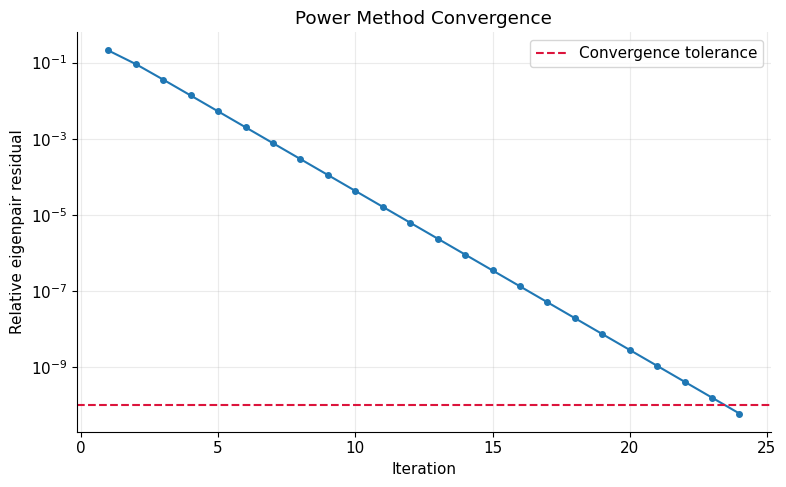

In [4]:
# Retrieve the residual recorded after each iteration.
residuals = power_result["residual_history"]
iterations = np.arange(1, len(residuals) + 1)

fig, ax = plt.subplots()

# Use a logarithmic vertical axis to show small residuals clearly.
ax.semilogy(iterations, residuals, marker="o", markersize=4)
ax.axhline(
    1e-10,
    color="crimson",
    linestyle="--",
    label="Convergence tolerance",
)

ax.set_title("Power Method Convergence")
ax.set_xlabel("Iteration")
ax.set_ylabel("Relative eigenpair residual")
ax.legend()

# Export the figure for the repository README.
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "power_method_convergence.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

### 2.3 Eigenvalue Analysis of a Nonsymmetric Matrix

Next, we analyze the following matrix:

$$
A =
\begin{bmatrix}
0 & 1 & 1 \\
\sqrt{2} & 2 & 0 \\
0 & 1 & 1
\end{bmatrix}
$$

NumPy computes its full eigendecomposition, while the Power Method
estimates only the dominant eigenpair.

Because this matrix is nonsymmetric, its eigenvectors are not
necessarily orthogonal. Each eigenpair is checked directly using
the eigenvalue equation.

In [5]:
# Define the second example matrix.
A_example = np.array([
    [0, 1, 1],
    [np.sqrt(2), 2, 0],
    [0, 1, 1],
], dtype=float)

example_values, example_vectors = np.linalg.eig(A_example)

# Sort eigenpairs together by descending eigenvalue magnitude.
order = np.argsort(np.abs(example_values))[::-1]
example_values = example_values[order]
example_vectors = example_vectors[:, order]

# Check the eigenvalue equation for every NumPy eigenpair.
example_residuals = np.array([
    np.linalg.norm(A_example @ vector - value * vector)
    / np.linalg.norm(A_example, ord="fro")
    for value, vector in zip(example_values, example_vectors.T)
])

display(pd.DataFrame({
    "Eigenvalue": example_values,
    "Relative residual": example_residuals,
}))

print("Eigenvectors (one per column):")
print(example_vectors)

# Compare the Power Method with NumPy's dominant eigenpair.
example_power = power_method(
    A_example,
    random_state=RANDOM_STATE,
)

example_direction_agreement = abs(
    example_power["eigenvector"] @ example_vectors[:, 0]
)

print("\nPower Method dominant eigenvalue:",
      example_power["eigenvalue"])
print("Iterations:", example_power["iterations"])
print("Converged:", example_power["converged"])
print(
    "Direction agreement:",
    f"{example_direction_agreement:.12f}",
)

# Validate both the full decomposition and dominant estimate.
assert np.all(example_residuals < 1e-10)
assert example_power["converged"]
assert np.isclose(
    example_power["eigenvalue"],
    example_values[0],
    rtol=1e-8,
    atol=1e-10,
)
assert np.isclose(
    example_direction_agreement,
    1.0,
    atol=1e-8,
)

print("All example-matrix eigenpair checks passed.")

,Eigenvalue,Relative residual
0,2.790044e+00,7.497089e-16
1,2.099560e-01,3.540332e-16
2,-2.633396e-19,3.627382e-16


Eigenvectors (one per column):
[[-0.43835   0.617311  0.707107]
 [-0.784665 -0.487703 -0.5     ]
 [-0.43835   0.617311  0.5     ]]

Power Method dominant eigenvalue: 2.790044015686291
Iterations: 10
Converged: True
Direction agreement: 1.000000000000
All example-matrix eigenpair checks passed.


## 3. Principal Component Analysis (PCA)

PCA finds orthogonal directions that capture the greatest variance
in a dataset.

Our implementation follows these steps:

1. Mean-center the features.
2. Compute the sample covariance matrix.
3. Compute its eigenvalues and eigenvectors.
4. Sort the components by decreasing explained variance.
5. Project the centered data onto the selected components.

Mean-centering subtracts each feature's mean; it does not scale features
to unit variance. We initially use centered, unscaled data to match
scikit-learn's default preprocessing.

Because the covariance matrix is symmetric, we use `np.linalg.eigh`
as the eigendecomposition building block.

In [6]:
def manual_pca(X, n_components):
    """Compute PCA using eigendecomposition of the covariance matrix."""
    X = np.asarray(X, dtype=float)

    # Validate the data and requested number of components.
    if X.ndim != 2 or X.shape[0] < 2 or X.shape[1] == 0:
        raise ValueError("X must contain at least two rows and one feature.")
    if not np.isfinite(X).all():
        raise ValueError("X must contain only finite values.")
    if not isinstance(n_components, (int, np.integer)):
        raise ValueError("n_components must be an integer.")
    if not 1 <= n_components <= min(X.shape):
        raise ValueError("n_components must be between 1 and min(X.shape).")

    # Center each feature without changing its scale.
    mean = X.mean(axis=0)
    centered = X - mean

    # Compute sample covariance, using n - 1 in the denominator.
    covariance = centered.T @ centered / (X.shape[0] - 1)

    # eigh returns eigenvectors in columns for a symmetric matrix.
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)

    # Sort eigenvalues and their corresponding vectors together.
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    # Remove tiny negative values caused by floating-point rounding.
    eigenvalues = np.clip(eigenvalues, 0.0, None)
    total_variance = eigenvalues.sum()

    if total_variance == 0:
        raise ValueError("PCA requires data with nonzero variance.")

    # Store components in rows, following scikit-learn's convention.
    components = eigenvectors[:, :n_components].T
    scores = centered @ components.T

    return {
        "mean": mean,
        "covariance": covariance,
        "components": components,
        "scores": scores,
        "explained_variance": eigenvalues[:n_components],
        "explained_variance_ratio": (
            eigenvalues[:n_components] / total_variance
        ),
        "all_explained_variance_ratio": eigenvalues / total_variance,
    }

### 3.1 Validate PCA on Synthetic Data

Generate reproducible data with two correlated features and retain
one principal component.

Compare explained variance and projected scores with scikit-learn.
Component signs may differ, so we align signs before comparing scores.

In [7]:
# Generate correlated data using a local random generator.
rng = np.random.default_rng(RANDOM_STATE)
X_synthetic = rng.multivariate_normal(
    mean=[0, 0],
    cov=[[3, 1], [1, 2]],
    size=100,
)

synthetic_manual = manual_pca(X_synthetic, n_components=1)

# Use the full SVD solver for an explicit reference implementation.
synthetic_sklearn = PCA(n_components=1, svd_solver="full")
synthetic_reference_scores = synthetic_sklearn.fit_transform(X_synthetic)

# Align the component signs before comparing projected coordinates.
component_dot = float(
    synthetic_manual["components"][0]
    @ synthetic_sklearn.components_[0]
)
sign = 1.0 if component_dot >= 0 else -1.0
aligned_scores = synthetic_manual["scores"] * sign

display(pd.DataFrame({
    "Method": ["Manual PCA", "scikit-learn PCA"],
    "PC1 explained variance": [
        synthetic_manual["explained_variance"][0],
        synthetic_sklearn.explained_variance_[0],
    ],
    "PC1 explained variance ratio": [
        synthetic_manual["explained_variance_ratio"][0],
        synthetic_sklearn.explained_variance_ratio_[0],
    ],
}))

print("Original shape:", X_synthetic.shape)
print("Reduced shape:", synthetic_manual["scores"].shape)
print(
    "Maximum score difference after sign alignment:",
    f"{np.max(np.abs(aligned_scores - synthetic_reference_scores)):.3e}",
)

# Verify the variance estimates and projected scores.
assert np.allclose(
    synthetic_manual["explained_variance"],
    synthetic_sklearn.explained_variance_,
    rtol=1e-8,
    atol=1e-10,
)
assert np.allclose(
    synthetic_manual["explained_variance_ratio"],
    synthetic_sklearn.explained_variance_ratio_,
    rtol=1e-8,
    atol=1e-10,
)
assert np.allclose(
    aligned_scores,
    synthetic_reference_scores,
    rtol=1e-8,
    atol=1e-10,
)

print("All synthetic PCA accuracy checks passed.")

,Method,PC1 explained variance,PC1 explained variance ratio
0,Manual PCA,3.049327,0.75821
1,scikit-learn PCA,3.049327,0.75821


Original shape: (100, 2)
Reduced shape: (100, 1)
Maximum score difference after sign alignment: 2.665e-15
All synthetic PCA accuracy checks passed.


### 3.2 Visualizing Dimensionality Reduction

Projecting onto one principal component retains the direction of greatest
variance. Mapping those scores back into the original feature space places
the reconstructed points along a line.

The variation perpendicular to that line is discarded.

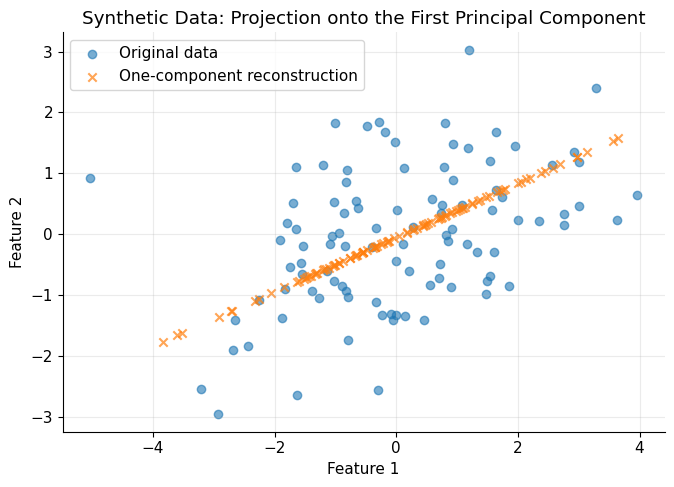

In [8]:
# Map the one-dimensional scores back to the original feature space.
synthetic_reconstructed = (
    synthetic_manual["scores"] @ synthetic_manual["components"]
    + synthetic_manual["mean"]
)

fig, ax = plt.subplots()

ax.scatter(
    X_synthetic[:, 0], X_synthetic[:, 1],
    alpha=0.6, label="Original data",
)
ax.scatter(
    synthetic_reconstructed[:, 0],
    synthetic_reconstructed[:, 1],
    alpha=0.7, marker="x", label="One-component reconstruction",
)

# Equal axis scaling preserves the geometry of the projection.
ax.set_aspect("equal", adjustable="box")
ax.set_title("Synthetic Data: Projection onto the First Principal Component")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.legend()

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "synthetic_pca_projection.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

### 3.3 PCA on the Iris Dataset

The Iris dataset contains 150 observations and four measurements:
sepal length, sepal width, petal length, and petal width.

We reduce the data to two principal components and compare our results
with scikit-learn. Species labels are used only for visualization;
they are not inputs to PCA.

The features are mean-centered without scaling to unit variance.
Consequently, features with greater variance can have more influence
on the resulting components.

In [9]:
# Load the feature measurements and species labels.
iris = load_iris()
X_iris = iris.data
y_iris = iris.target

iris_manual = manual_pca(X_iris, n_components=2)

iris_sklearn = PCA(n_components=2, svd_solver="full")
iris_reference_scores = iris_sklearn.fit_transform(X_iris)

# Align each component's sign with the reference.
component_dots = np.sum(
    iris_manual["components"] * iris_sklearn.components_,
    axis=1,
)
signs = np.where(component_dots >= 0, 1.0, -1.0)
iris_aligned_scores = iris_manual["scores"] * signs

display(pd.DataFrame({
    "Component": ["PC1", "PC2"],
    "Manual explained variance ratio":
        iris_manual["explained_variance_ratio"],
    "scikit-learn explained variance ratio":
        iris_sklearn.explained_variance_ratio_,
}))

print("Original shape:", X_iris.shape)
print("Reduced shape:", iris_manual["scores"].shape)
print(
    "Variance retained by two components:",
    f"{iris_manual['explained_variance_ratio'].sum():.2%}",
)
print(
    "Maximum score difference after sign alignment:",
    f"{np.max(np.abs(iris_aligned_scores - iris_reference_scores)):.3e}",
)

# Validate variance estimates, scores, and component orthonormality.
assert np.allclose(
    iris_manual["explained_variance"],
    iris_sklearn.explained_variance_,
    rtol=1e-8,
    atol=1e-10,
)
assert np.allclose(
    iris_manual["explained_variance_ratio"],
    iris_sklearn.explained_variance_ratio_,
    rtol=1e-8,
    atol=1e-10,
)
assert np.allclose(
    iris_aligned_scores,
    iris_reference_scores,
    rtol=1e-8,
    atol=1e-10,
)
assert np.allclose(
    iris_manual["components"] @ iris_manual["components"].T,
    np.eye(2),
    atol=1e-10,
)

print("All Iris PCA accuracy checks passed.")

,Component,Manual explained variance ratio,scikit-learn explained variance ratio
0,PC1,0.924619,0.924619
1,PC2,0.053066,0.053066


Original shape: (150, 4)
Reduced shape: (150, 2)
Variance retained by two components: 97.77%
Maximum score difference after sign alignment: 3.109e-15
All Iris PCA accuracy checks passed.


### 3.4 Iris Projection and Explained Variance

The two-dimensional projection shows how the observations are arranged
along the principal components. Species labels provide visual context,
but PCA does not use them when finding these directions.

The explained variance chart shows the information retained by each
component and the cumulative proportion across all four components.

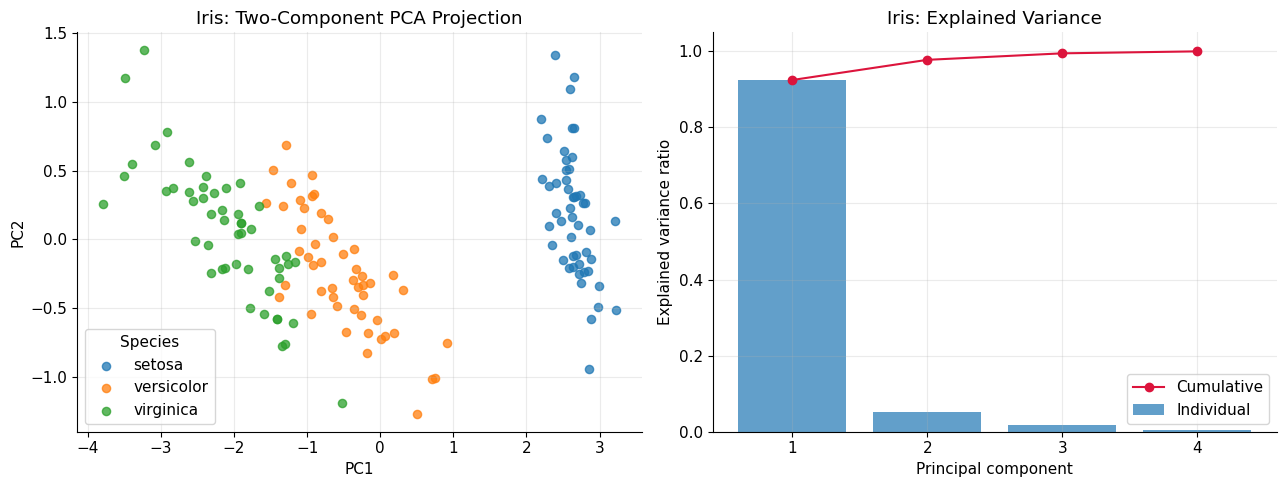

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot the manual PCA scores, colored by species.
for species_id, species_name in enumerate(iris.target_names):
    mask = y_iris == species_id
    axes[0].scatter(
        iris_manual["scores"][mask, 0],
        iris_manual["scores"][mask, 1],
        label=species_name,
        alpha=0.75,
        s=35,
    )

axes[0].set_title("Iris: Two-Component PCA Projection")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")
axes[0].legend(title="Species")

# Show individual and cumulative variance for all components.
variance_ratios = iris_manual["all_explained_variance_ratio"]
component_numbers = np.arange(1, len(variance_ratios) + 1)

axes[1].bar(
    component_numbers,
    variance_ratios,
    alpha=0.7,
    label="Individual",
)
axes[1].plot(
    component_numbers,
    np.cumsum(variance_ratios),
    color="crimson",
    marker="o",
    label="Cumulative",
)

axes[1].set_title("Iris: Explained Variance")
axes[1].set_xlabel("Principal component")
axes[1].set_ylabel("Explained variance ratio")
axes[1].set_xticks(component_numbers)
axes[1].set_ylim(0, 1.05)
axes[1].legend()

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "iris_pca_analysis.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

### 3.5 Interpreting Component Weights

Component weights describe how the centered features combine to form
each principal component. Larger absolute weights indicate a stronger
contribution to that component's direction.

These weights are calculated directly from the fitted components.
Their overall signs are arbitrary: reversing a component's sign also
reverses its scores without changing the PCA solution.

Component weights describe variance structure, not predictive feature
importance or causal relationships.

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
PC1,-0.361387,0.084523,-0.856671,-0.358289
PC2,0.656589,0.730161,-0.173373,-0.075481


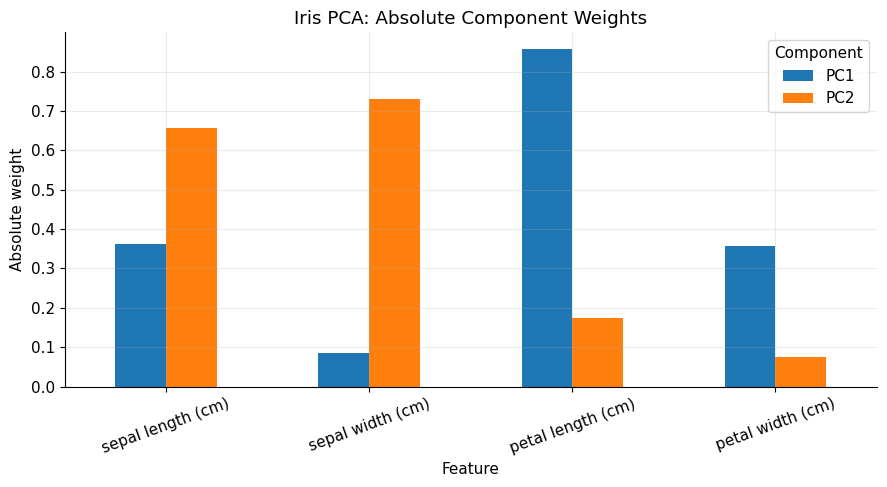

In [11]:
# Generate the weight table from the computed components.
iris_weights = pd.DataFrame(
    iris_manual["components"],
    columns=iris.feature_names,
    index=["PC1", "PC2"],
)

display(iris_weights)

# Compare absolute weights because component signs are arbitrary.
ax = iris_weights.abs().T.plot.bar(figsize=(9, 5))

ax.set_title("Iris PCA: Absolute Component Weights")
ax.set_xlabel("Feature")
ax.set_ylabel("Absolute weight")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Component")

fig = ax.get_figure()
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "iris_pca_component_weights.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

### PCA Findings

- PC1 explains approximately 92.46% of the variance, and PC2 explains
  approximately 5.31%. Together, they retain 97.77%.
- The manual implementation matches scikit-learn's explained variance
  and projected scores after component sign alignment.
- PC1 has its largest absolute weight on petal length.
- PC2 has its largest absolute weights on sepal width and sepal length.
- The projection separates setosa clearly, while versicolor and virginica
  show overlap. PCA does not guarantee class separation.
- These findings apply to centered, unscaled Iris measurements.
  Scaling features to unit variance would change the PCA solution.

## 4. Singular Value Decomposition (SVD)

SVD expresses a real matrix as:

$$
A = U \Sigma V^T
$$

Our educational implementation uses the eigendecomposition of
$A^T A$ to obtain the right singular vectors and squared singular values.

For each retained nonzero singular value, the corresponding left
singular vector is calculated using:

$$
u_i = \frac{A v_i}{\sigma_i}
$$

This keeps the left and right vectors correctly paired. Independently
computing them and sorting only the singular values can produce an
incorrect reconstruction.

We return a compact decomposition containing only numerically nonzero
singular values. Eigenvalues below a floating-point threshold are treated
as zero.

Forming $A^T A$ squares the condition number, making this approach less
reliable for ill-conditioned matrices. NumPy's direct SVD is preferred
for production work.

In [12]:
def manual_svd(A):
    """Construct a compact SVD through eigendecomposition of A.T @ A."""
    A = np.asarray(A, dtype=float)

    # Validate the input matrix.
    if A.ndim != 2 or min(A.shape) == 0:
        raise ValueError("A must be a nonempty two-dimensional matrix.")
    if not np.isfinite(A).all():
        raise ValueError("A must contain only finite values.")

    # The Gram matrix is symmetric and positive semidefinite.
    gram = A.T @ A
    eigenvalues, eigenvectors = np.linalg.eigh(gram)

    # Keep each eigenvector paired with its eigenvalue.
    order = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[order]
    eigenvectors = eigenvectors[:, order]

    # Define a scale-dependent threshold for numerical zero.
    largest_value = max(float(eigenvalues[0]), 0.0)
    eigenvalue_tol = (
        np.finfo(float).eps * max(A.shape) * largest_value
    )

    # Significant negative eigenvalues would indicate numerical failure.
    if np.any(eigenvalues < -eigenvalue_tol):
        raise ValueError("Gram matrix has a significant negative eigenvalue.")

    # Retain only numerically positive eigenvalues.
    keep = eigenvalues > eigenvalue_tol
    singular_values = np.sqrt(eigenvalues[keep])
    V = eigenvectors[:, keep]

    # Derive U from V to preserve vector ordering and sign alignment.
    U = (A @ V) / singular_values
    VT = V.T

    return {
        "U": U,
        "singular_values": singular_values,
        "VT": VT,
        "rank": len(singular_values),
        "eigenvalue_tolerance": eigenvalue_tol,
    }

### 4.1 Validate SVD on Two Example Matrices

We evaluate a rectangular full-rank matrix and the rank-deficient
matrix used earlier.

Validation checks include:

- Agreement with NumPy's singular values.
- Reconstruction of the original matrix.
- Orthonormality of the retained singular vectors.

The rank-deficient example has only two retained singular values.
Its omitted zero singular value contributes nothing to reconstruction.

In [13]:
A_rectangular = np.array([
    [3, 1],
    [2, 2],
    [1, 3],
], dtype=float)

svd_examples = {
    "Rectangular matrix": A_rectangular,
    "Rank-deficient matrix": A_example,
}

svd_results = {}
validation_rows = []

for name, matrix in svd_examples.items():
    result = manual_svd(matrix)
    svd_results[name] = result

    # Compute NumPy's reference decomposition.
    U_np, values_np, VT_np = np.linalg.svd(
        matrix, full_matrices=False
    )

    # Scale U's columns by the singular values before multiplying by VT.
    reconstructed = (
        result["U"] * result["singular_values"]
    ) @ result["VT"]

    relative_error = (
        np.linalg.norm(matrix - reconstructed, ord="fro")
        / np.linalg.norm(matrix, ord="fro")
    )

    rank = result["rank"]
    singular_value_error = np.max(
        np.abs(result["singular_values"] - values_np[:rank])
    )

    validation_rows.append({
        "Matrix": name,
        "Retained rank": rank,
        "Relative reconstruction error": relative_error,
        "Maximum singular value error": singular_value_error,
    })

    print(f"\n{name}")
    print("Manual singular values:", result["singular_values"])
    print("NumPy singular values:", values_np)
    print("Reconstructed matrix:\n", reconstructed)

    # Confirm retained values agree and omitted values are negligible.
    assert np.allclose(
        result["singular_values"], values_np[:rank],
        rtol=1e-8, atol=1e-10,
    )
    assert np.allclose(values_np[rank:], 0.0, atol=1e-10)
    assert relative_error < 1e-10

    # Check orthonormality of the compact singular-vector matrices.
    assert np.allclose(
        result["U"].T @ result["U"],
        np.eye(rank),
        atol=1e-10,
    )
    assert np.allclose(
        result["VT"] @ result["VT"].T,
        np.eye(rank),
        atol=1e-10,
    )

display(pd.DataFrame(validation_rows))
print("All example SVD accuracy checks passed.")


Rectangular matrix
Manual singular values: [4.898979 2.      ]
NumPy singular values: [4.898979 2.      ]
Reconstructed matrix:
 [[3. 1.]
 [2. 2.]
 [1. 3.]]

Rank-deficient matrix
Manual singular values: [2.828427 1.414214]
NumPy singular values: [2.828427 1.414214 0.      ]
Reconstructed matrix:
 [[-0.        1.        1.      ]
 [ 1.414214  2.        0.      ]
 [-0.        1.        1.      ]]


,Matrix,Retained rank,Relative reconstruction error,Maximum singular value error
0,Rectangular matrix,2,1.780318e-16,4.440892e-16
1,Rank-deficient matrix,2,2.108169e-16,0.000000e+00


All example SVD accuracy checks passed.


### 4.2 Low-Rank Approximation

Keeping only the largest singular values produces a lower-rank
approximation of a matrix:

$$
A_k = U_k \Sigma_k V_k^T
$$

The retained squared singular values measure the proportion of the
matrix's Frobenius energy preserved. For a mean-centered data matrix,
this also corresponds to the proportion of variance retained by PCA.

Here, we compare reconstruction error and retained energy for the
rank-deficient example matrix.

,Retained rank,Retained energy,Relative reconstruction error
0,1,0.8,4.472136e-01
1,2,1.0,2.108169e-16


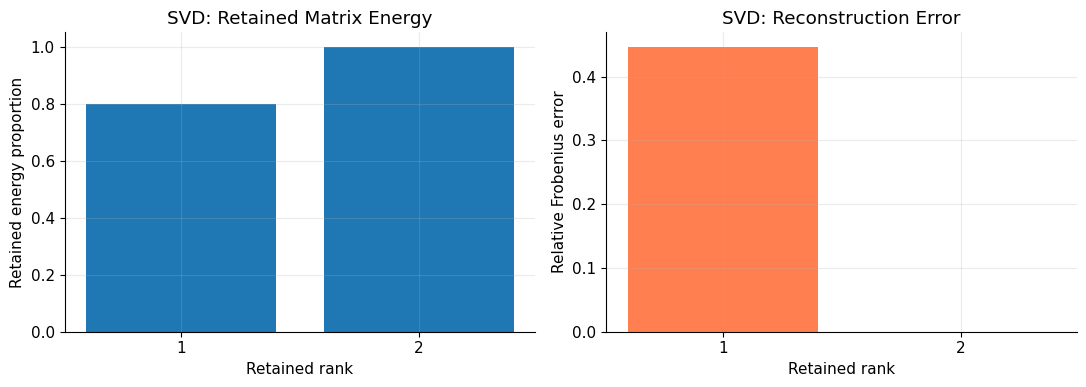

In [14]:
# Use the validated decomposition of the rank-deficient matrix.
example_svd = svd_results["Rank-deficient matrix"]
singular_values = example_svd["singular_values"]

approximation_rows = []

for k in range(1, example_svd["rank"] + 1):
    # Reconstruct using only the first k singular-vector pairs.
    approximation = (
        example_svd["U"][:, :k] * singular_values[:k]
    ) @ example_svd["VT"][:k, :]

    relative_error = (
        np.linalg.norm(A_example - approximation, ord="fro")
        / np.linalg.norm(A_example, ord="fro")
    )

    retained_energy = (
        np.sum(singular_values[:k] ** 2)
        / np.sum(singular_values ** 2)
    )

    approximation_rows.append({
        "Retained rank": k,
        "Retained energy": retained_energy,
        "Relative reconstruction error": relative_error,
    })

approximation_summary = pd.DataFrame(approximation_rows)
display(approximation_summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Compare the information retained at each approximation rank.
axes[0].bar(
    approximation_summary["Retained rank"],
    approximation_summary["Retained energy"],
)
axes[0].set_title("SVD: Retained Matrix Energy")
axes[0].set_xlabel("Retained rank")
axes[0].set_ylabel("Retained energy proportion")
axes[0].set_ylim(0, 1.05)

# Show how reconstruction improves as more components are retained.
axes[1].bar(
    approximation_summary["Retained rank"],
    approximation_summary["Relative reconstruction error"],
    color="coral",
)
axes[1].set_title("SVD: Reconstruction Error")
axes[1].set_xlabel("Retained rank")
axes[1].set_ylabel("Relative Frobenius error")

for ax in axes:
    ax.set_xticks(approximation_summary["Retained rank"])

fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "svd_low_rank_approximation.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

### 4.3 Connecting SVD and PCA

For a mean-centered dataset X, the sample covariance matrix is:

$$
C = \frac{X^T X}{n - 1}
$$

The right singular vectors of X define its principal component
directions. Its singular values determine the PCA explained variances:

$$
\lambda_i = \frac{\sigma_i^2}{n - 1}
$$

We verify this relationship using the Iris dataset.

In [15]:
# Center Iris exactly as in the manual PCA implementation.
iris_centered = X_iris - iris_manual["mean"]
iris_svd = manual_svd(iris_centered)

# Convert squared singular values into sample covariance eigenvalues.
svd_explained_variance = (
    iris_svd["singular_values"] ** 2
    / (X_iris.shape[0] - 1)
)

display(pd.DataFrame({
    "Component": ["PC1", "PC2"],
    "Covariance PCA explained variance":
        iris_manual["explained_variance"],
    "SVD-derived explained variance":
        svd_explained_variance[:2],
}))

# Compare component directions while allowing sign differences.
direction_agreements = np.abs(np.sum(
    iris_manual["components"] * iris_svd["VT"][:2],
    axis=1,
))

print("Component direction agreements:", direction_agreements)

assert np.allclose(
    svd_explained_variance[:2],
    iris_manual["explained_variance"],
    rtol=1e-8,
    atol=1e-10,
)
assert np.allclose(direction_agreements, 1.0, atol=1e-8)

print("PCA–SVD relationship checks passed.")

,Component,Covariance PCA explained variance,SVD-derived explained variance
0,PC1,4.228242,4.228242
1,PC2,0.242671,0.242671


Component direction agreements: [1. 1.]
PCA–SVD relationship checks passed.


## 5. Runtime Comparisons

We measure complete function calls using `perf_counter`, excluding
printing, plotting, and data generation.

Each method is warmed up before timing. Multiple calls are measured
in each batch, and several batches are repeated. We report the median
time per call and the interquartile range (IQR).

These measurements describe performance on this computer and these
small inputs. They do not establish general performance rankings.

Comparison scope:

- **Eigenvalues:** The Power Method estimates one dominant eigenpair;
  NumPy computes all eigenpairs. Their workloads differ.
- **PCA:** Both methods fit and project Iris onto two components.
- **SVD:** Both methods compute singular values and vectors. The manual
  method returns retained nonzero components; NumPy uses reduced SVD.

The educational functions also include input validation and diagnostic
outputs, which contribute to their runtimes.

In [16]:
def benchmark_function(function, repeats=9, calls_per_repeat=100):
    """Measure median time per call and variability across batches."""
    # Warm up the function before collecting measurements.
    for _ in range(5):
        function()

    batch_times = []

    for _ in range(repeats):
        start = perf_counter()

        # Batch small operations to reduce timer overhead per call.
        for _ in range(calls_per_repeat):
            function()

        elapsed = perf_counter() - start
        batch_times.append(elapsed / calls_per_repeat)

    # Convert seconds per call into microseconds.
    times_us = np.array(batch_times) * 1e6
    q1, q3 = np.percentile(times_us, [25, 75])

    return {
        "Median time (µs)": np.median(times_us),
        "IQR (µs)": q3 - q1,
        "Q1 (µs)": q1,
        "Q3 (µs)": q3,
    }


# Use fixed inputs already validated in the notebook.
benchmark_cases = [
    (
        "Eigenpair",
        "Power Method",
        lambda: power_method(A_demo, random_state=RANDOM_STATE),
    ),
    (
        "Eigenpair",
        "NumPy eig",
        lambda: np.linalg.eig(A_demo),
    ),
    (
        "PCA",
        "Manual PCA",
        lambda: manual_pca(X_iris, n_components=2),
    ),
    (
        "PCA",
        "scikit-learn PCA",
        lambda: PCA(
            n_components=2, svd_solver="full"
        ).fit_transform(X_iris),
    ),
    (
        "SVD",
        "Manual SVD",
        lambda: manual_svd(A_rectangular),
    ),
    (
        "SVD",
        "NumPy SVD",
        lambda: np.linalg.svd(
            A_rectangular, full_matrices=False
        ),
    ),
]

benchmark_rows = []

for task, method, function in benchmark_cases:
    # Measure computation only; display results after timing finishes.
    measurements = benchmark_function(function)
    benchmark_rows.append({
        "Task": task,
        "Method": method,
        **measurements,
    })

benchmark_summary = pd.DataFrame(benchmark_rows)

display(benchmark_summary[
    ["Task", "Method", "Median time (µs)", "IQR (µs)"]
])

,Task,Method,Median time (µs),IQR (µs)
0,Eigenpair,Power Method,361.162000,50.861998
1,Eigenpair,NumPy eig,13.800999,0.188001
2,PCA,Manual PCA,41.609001,1.282999
3,PCA,scikit-learn PCA,228.010998,45.297998
4,SVD,Manual SVD,28.697997,2.750000
5,SVD,NumPy SVD,8.839001,3.543994


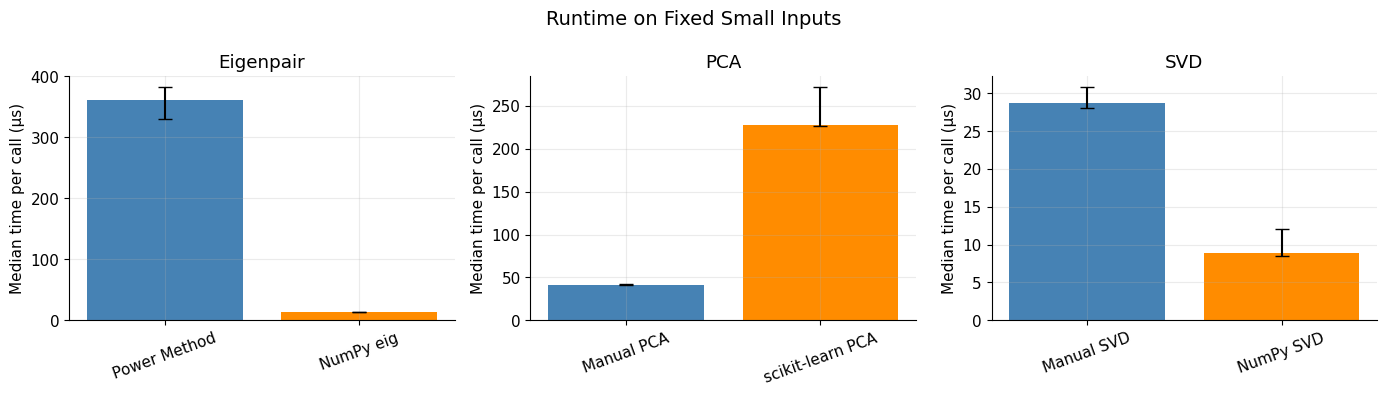

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, task in zip(axes, ["Eigenpair", "PCA", "SVD"]):
    subset = benchmark_summary[
        benchmark_summary["Task"] == task
    ]
    medians = subset["Median time (µs)"].to_numpy()

    # Error bars show the first and third quartiles across batches.
    error_bars = np.vstack([
        medians - subset["Q1 (µs)"].to_numpy(),
        subset["Q3 (µs)"].to_numpy() - medians,
    ])

    ax.bar(
        subset["Method"],
        medians,
        yerr=error_bars,
        capsize=5,
        color=["steelblue", "darkorange"],
    )
    ax.set_title(task)
    ax.set_ylabel("Median time per call (µs)")
    ax.tick_params(axis="x", rotation=20)

fig.suptitle("Runtime on Fixed Small Inputs", fontsize=14)
fig.tight_layout()
fig.savefig(
    FIGURES_DIR / "runtime_comparison.png",
    dpi=200,
    bbox_inches="tight",
)
plt.show()

### 5.1 Runtime Findings

Median times per call in this run:

| Task | Educational implementation | Reference library |
|---|---:|---:|
| Eigenpair computation | Power Method: 361.16 µs | NumPy eig: 13.80 µs |
| PCA | Manual PCA: 41.61 µs | scikit-learn PCA: 228.01 µs |
| SVD | Manual SVD: 28.70 µs | NumPy SVD: 8.84 µs |

- NumPy's eigensolver was faster on the 2 × 2 example despite computing
  all eigenpairs. The Power Method includes a Python iteration loop,
  random initialization, and residual tracking.
- Manual covariance-based PCA was faster on Iris, which has only four
  features. The implementations use different solvers and have different
  validation and estimator overhead.
- NumPy's direct SVD was faster on the 3 × 2 example and avoids the
  numerical limitations of forming a Gram matrix.
- These small-input benchmarks do not show how the methods scale.
  Results depend on hardware, library versions, and system activity.

## 6. Conclusions and Limitations

### Main Findings

- The Power Method matched NumPy's dominant eigenpairs for both examples.
  Residual checks confirmed convergence within the chosen tolerance.
- Covariance-based PCA matched scikit-learn's explained variances and
  projected scores after sign alignment.
- Two principal components retained approximately 97.77% of the variance
  in centered, unscaled Iris measurements.
- The corrected compact SVD reconstructed both example matrices with
  relative errors near floating-point precision.
- The Iris analysis verified that PCA component directions correspond
  to right singular vectors of centered data, with explained variances
  given by squared singular values divided by n − 1.

### Limitations

- The Power Method estimates one dominant eigenpair and does not
  converge reliably for every matrix or starting vector.
- PCA depends on feature scaling. The Iris results here use
  mean-centering without scaling to unit variance.
- Gram-matrix SVD can lose accuracy for small singular values because
  forming AᵀA squares the condition number. Its numerical threshold
  can discard weak components.
- Runtime measurements cover small, fixed inputs rather than a
  systematic scalability study.

The implementations illustrate the mathematical steps and are validated
on the examples in this notebook. Established numerical libraries remain
the preferred choice for production applications.